# PAIR50E：50 epoch 模型的十分层回测

读取 `model2_output/PAIR_rank` 中的四种信号，分别建立从低分到高分的十个等权组合。40 本账共享同一遍行情循环，使用 `TOOL/book.py` 的 `PortfolioBook` 在每天开盘调仓。

回测区间为 2023-01-03 至 2026-09-30，初始净值为 1，单边费率为 0.00025；跨年连续持仓。末日净值截至开盘调仓后。结果保存到 `model2_output/backtest`。

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm

from TOOL.data import preload, load_market, date_path, MODEL_OUTPUT_PATH, BACKTEST_PATH
from TOOL.backtest import PortfolioBook, save_books
from TOOL.show_book import show_book

In [6]:
from pathlib import Path

MODEL_OUTPUT_PATH=Path("/home/wenjy/FactorTrans/WORKFILE/model2_output")
BACKTEST_PATH=MODEL_OUTPUT_PATH / "backtest"

In [7]:
ALPHA_LIST = ['model', 'rank_5', 'rank_10', 'rank_20']
years_list = ['2023', '2024', '2025', '2026']
books = {alpha: [PortfolioBook(fee_per_side=0.00025) for _ in range(10)] for alpha in ALPHA_LIST}
base_info, dates_list, dates_path_list = preload(years_list)
factors_path_list = [date_path(MODEL_OUTPUT_PATH / 'PAIR_rank', date) for date in dates_list]
BACKTEST_PATH.mkdir(parents=True, exist_ok=True)

## 分层、调仓与权重保存

按信号分位数区间 `(g/10, (g+1)/10]` 划分第 g+1 组，再筛选当日在市股票并分配等权。第 1 组分数最低，第 10 组最高。并列分数取平均名次，不强制每组人数相等。

每天只读取一次行情和一次四列信号，再更新 40 本账。目标权重保存到 `backtest/weights/年份/日期.parquet`，可与信号和组合收益逐日对应。

In [8]:
for date, market_path, factor_path in tqdm(
    list(zip(dates_list, dates_path_list, factors_path_list)), mininterval=30
):
    listed_info = load_market(date, market_path, base_info, ['open', 'close', 'high', 'prev_close'])
    factor_info = pd.read_parquet(factor_path).set_index('order_book_id')

    #=======
    weights_today = []
    for alpha in ALPHA_LIST:
        rank = factor_info[alpha]
        for group in range(10):
            low = group / 10
            high = (group + 1) / 10
            weights = pd.Series(1.0, index=rank.index[(rank > low) & (rank <= high)])
            weights = weights[weights.index.isin(listed_info['order_book_id'])]
            if len(weights) != 0:
                weights = weights / len(weights)
            books[alpha][group].step(listed_info, weights)
            weights_today.append(weights.rename('weight').rename_axis('order_book_id').reset_index().assign(
                factor=alpha, group=group + 1, datetime=date
            ))
    year_path = BACKTEST_PATH / 'weights' / date[:4]
    year_path.mkdir(parents=True, exist_ok=True)
    pd.concat(weights_today, ignore_index=True).to_parquet(
        year_path / f"{date.replace('-', '')}.parquet", compression='zstd', index=False
    )
    #=======

100%|██████████| 908/908 [25:23<00:00,  1.68s/it]


## 组合记录与绩效汇总

每本账的逐日净值、收益、成交金额、手续费、退市损益和持仓数保存为 Parquet。`summary.csv` 汇总全期表现，`summary_by_year.csv` 从连续账本中计算各年表现，年初不重置资金。

下表展示十个分组的最终净值；曲线用于观察收益梯度、分层稳定性和共同回撤。

In [9]:
summary = save_books(books, BACKTEST_PATH)
summary.pivot(index='group', columns='factor', values='equity')

factor,model,rank_10,rank_20,rank_5
group,,,,
1,0.356967,0.593946,0.779786,0.471719
2,0.837342,0.920967,1.096646,0.874043
3,1.135511,1.195499,1.151709,1.198555
4,1.250590,1.346992,1.370129,1.340734
5,1.414972,1.419619,1.297977,1.466939
6,1.388906,1.429464,1.425763,1.511661
7,1.575557,1.615751,1.476801,1.615643
8,1.761547,1.924928,1.863520,1.833938
9,1.955732,2.037054,2.040839,2.057657


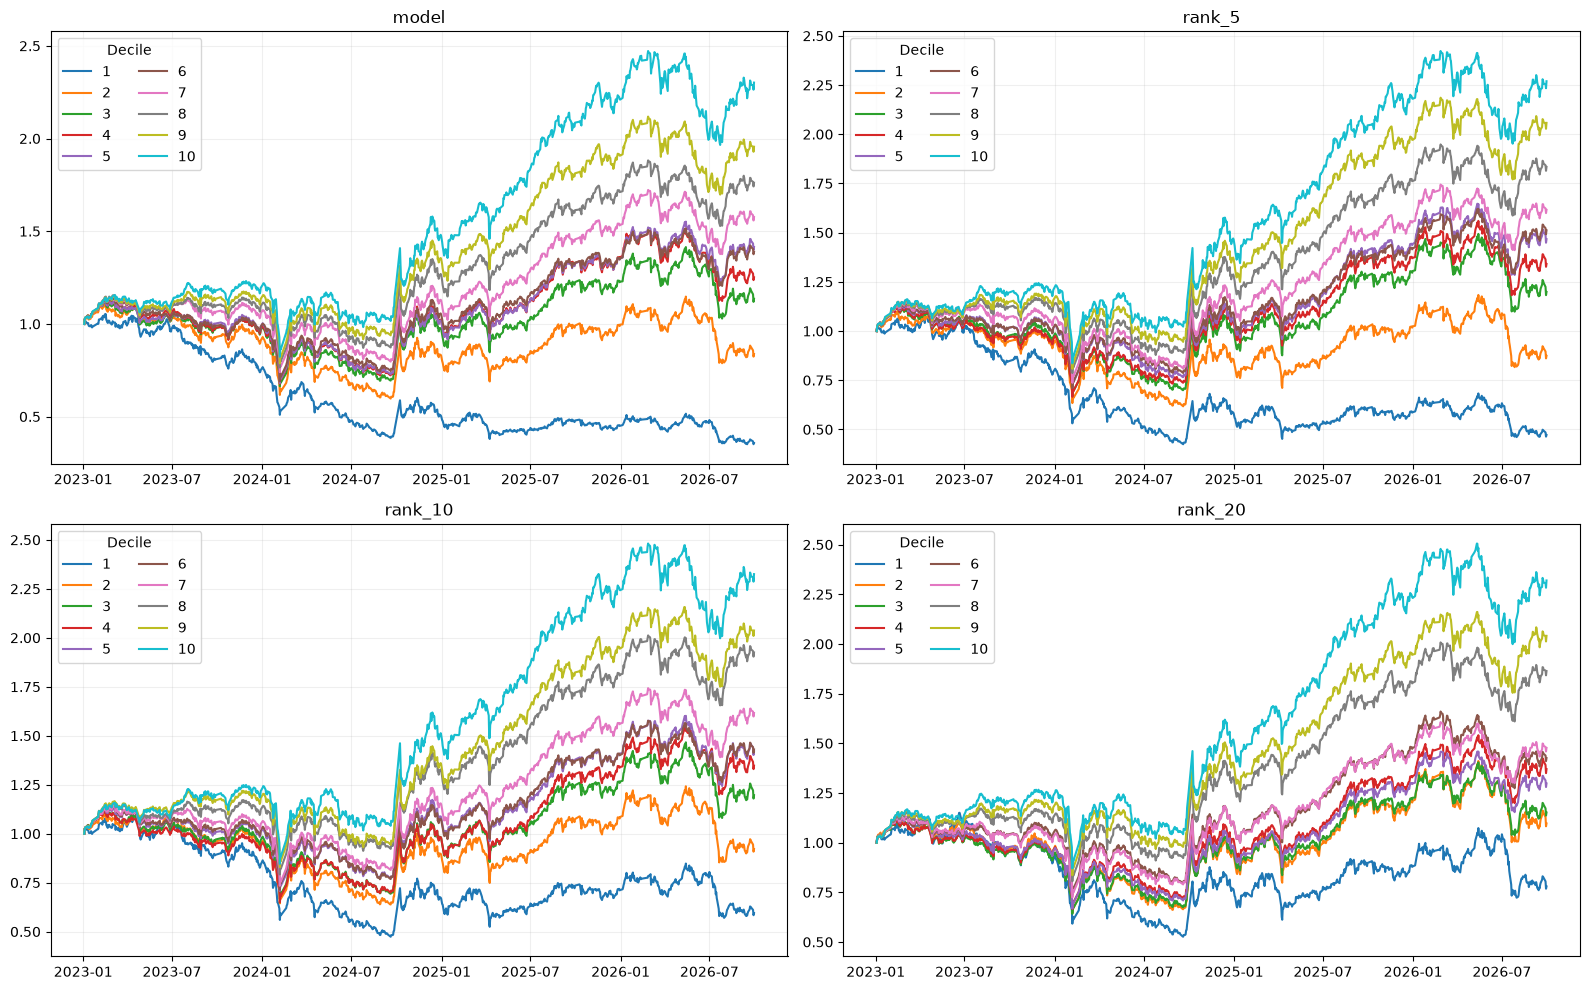

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, alpha in zip(axes.flat, ALPHA_LIST):
    for group, book in enumerate(books[alpha], 1):
        history = book.to_frame()
        ax.plot(history['date'], history['equity'], label=str(group))
    ax.set_title(alpha)
    ax.legend(title='Decile', ncol=2)
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(BACKTEST_PATH / 'deciles.png', dpi=160)
plt.grid()
plt.show()

## 查看曲线与单组报告

下方嵌入 `deciles.png`，打开 Notebook 即可查看已保存的四种信号分层曲线。单组详细报告可调用 `show_book(books["rank_20"][9])`，其中列表索引 9 对应第 10 组。

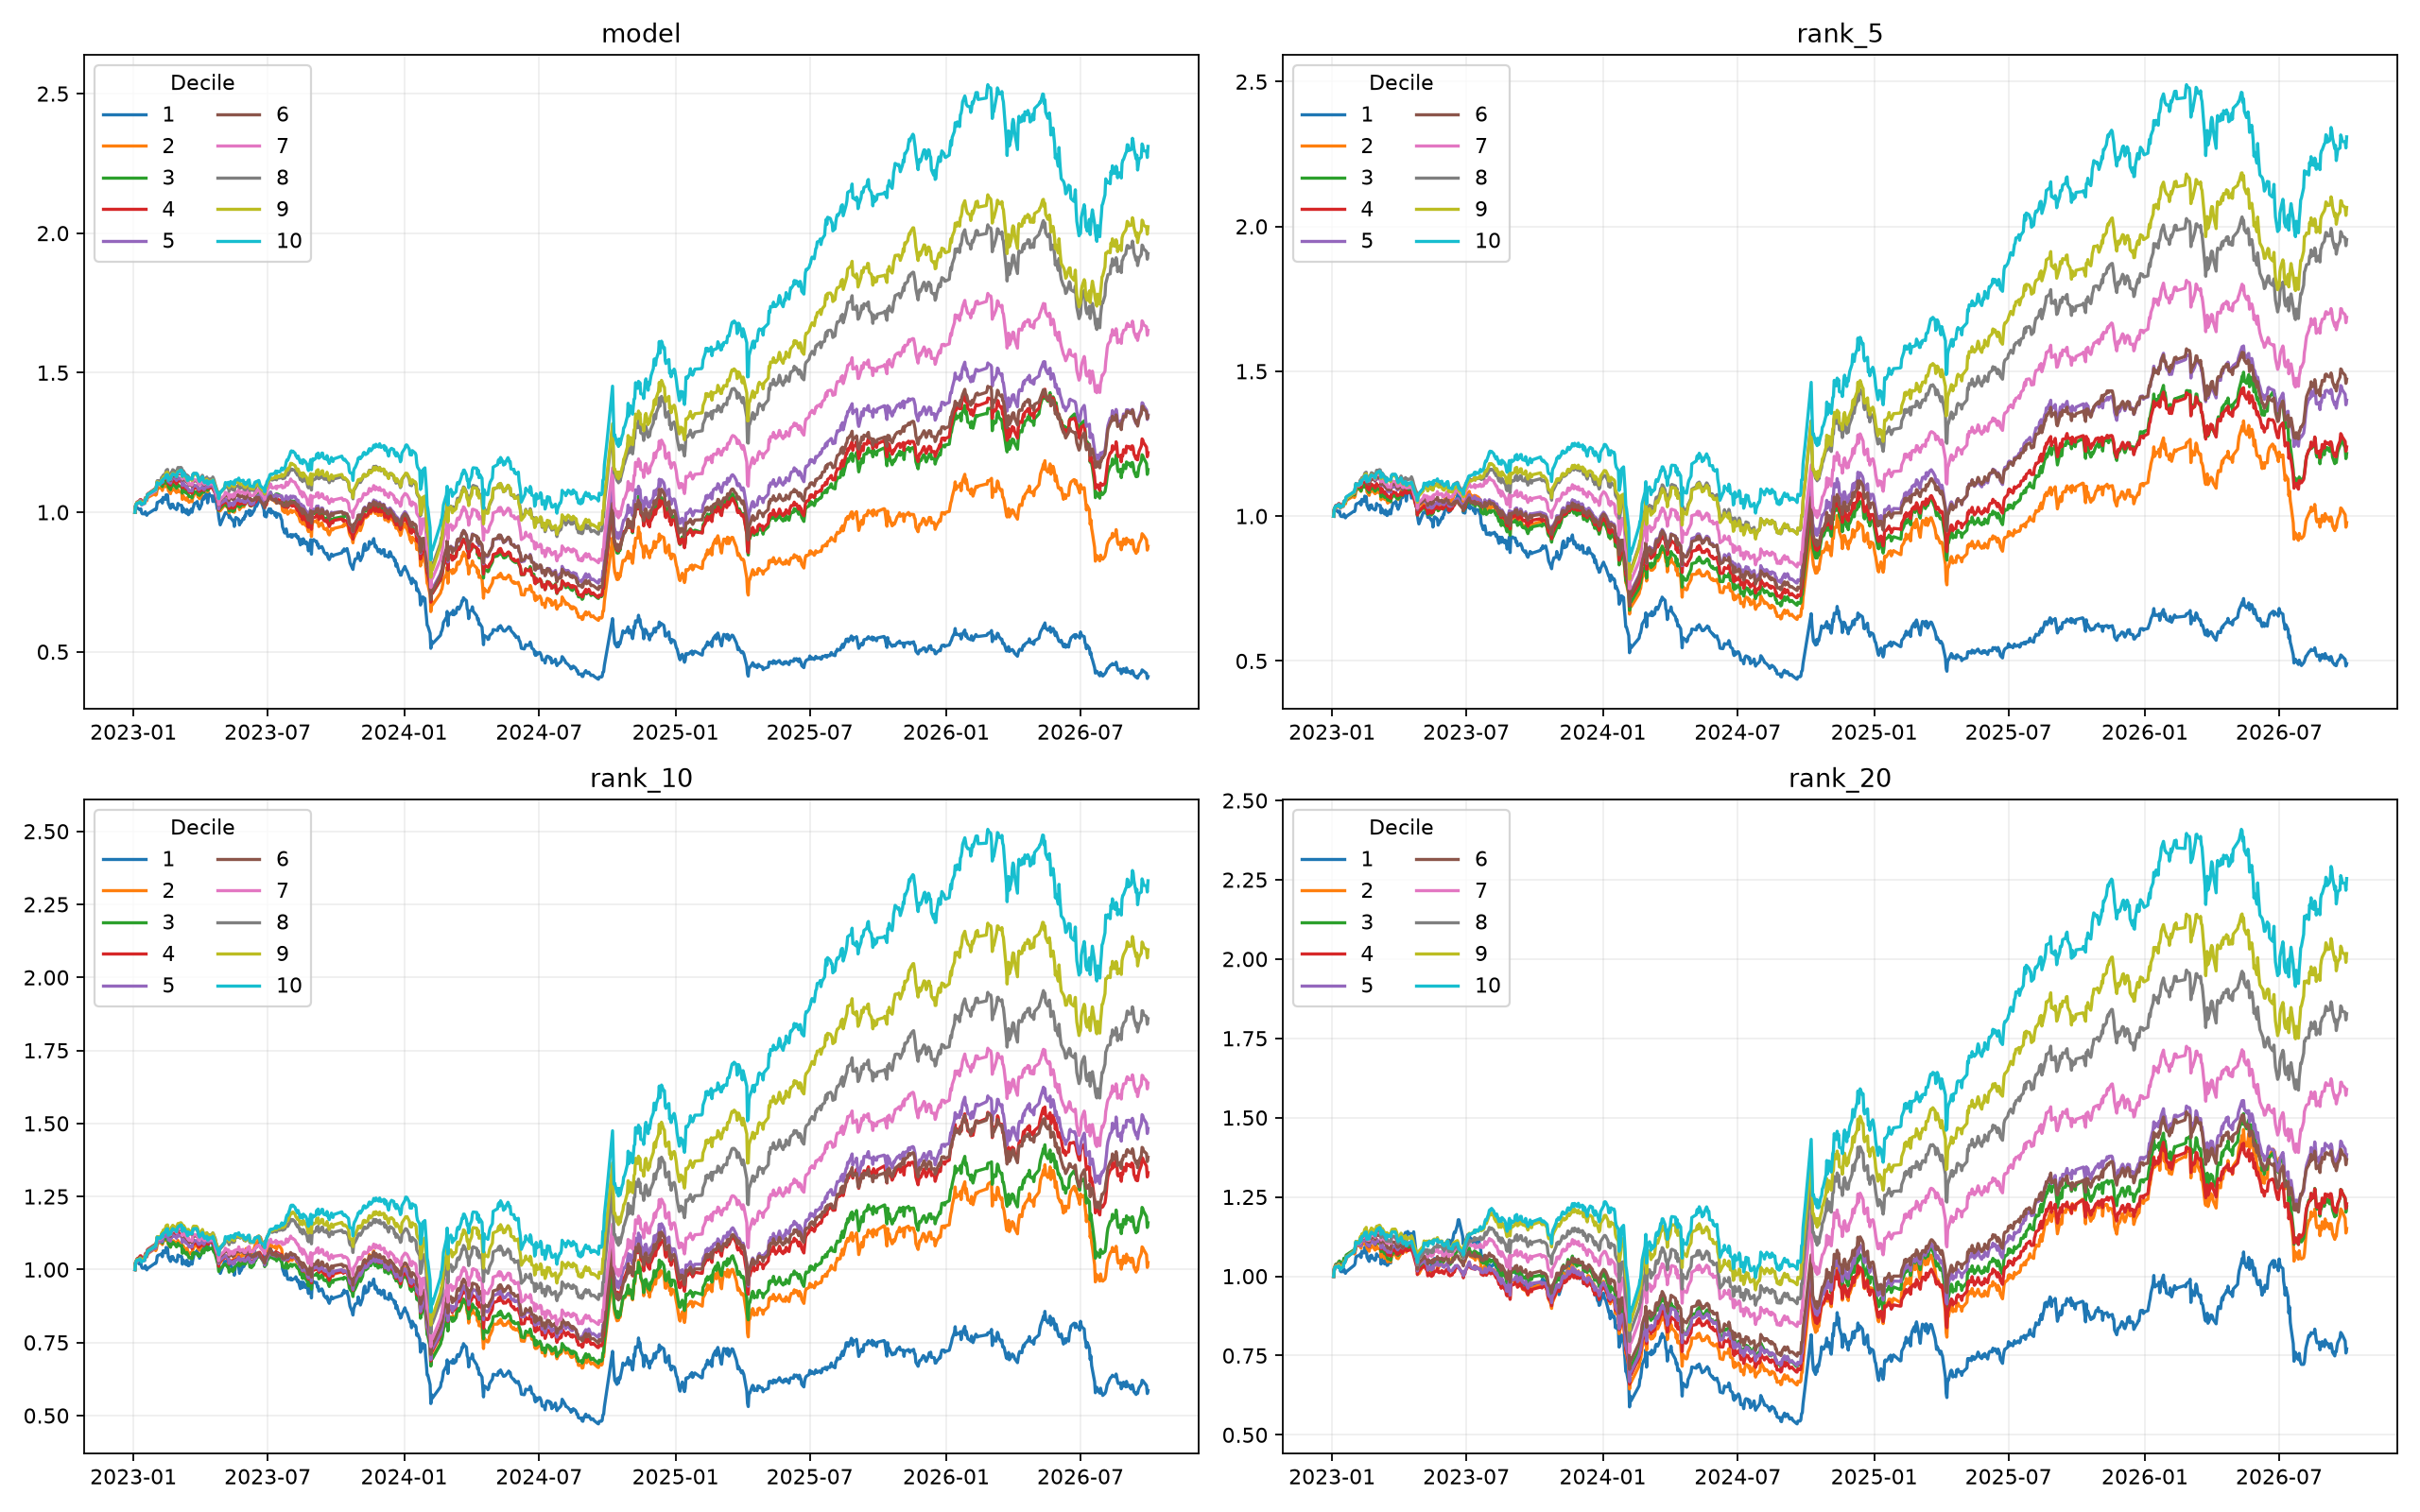

In [4]:
from IPython.display import Image, display

display(Image(filename=str(BACKTEST_PATH / 'deciles.png')))

## 高低分组的净值差

以下将第 10−1、9−2、8−3、7−4 组的净值分别相减，观察分层间距随时间的变化。这是两条净值曲线的差，不是独立多空组合的净值或收益率；横轴为交易日序号。

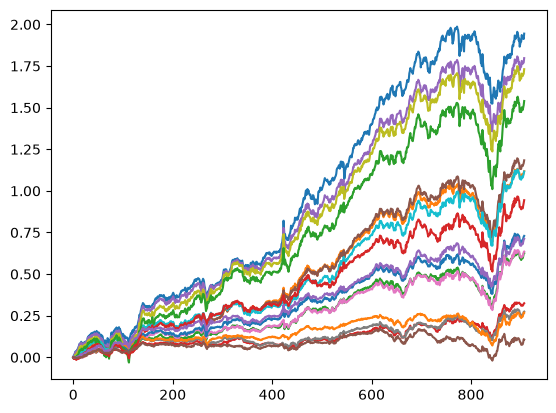

In [21]:
for i in books.keys():
    for top,bot in zip([9,8,7,6],[0,1,2,3]):
        plt.plot(books[i][top].to_frame()['equity']-books[i][bot].to_frame()['equity'])